# Yambda 04 · Collaborative filtering: ALS and ItemKNN

Questions, carried over from Last.fm:
1. Does time decay matter here too? (ALS sweep over half-life × alpha)
2. Does ALS / ItemKNN beat the best popularity baseline?
3. Does the "familiar artist" pattern replicate? (segment analysis + fair new-artist comparison)

Runtime: ALS ~30-60 s per model (10-12 models), ItemKNN ~4-6 min per model (2 models). Total roughly 20-25 min.

In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt
from musicrec import config
from musicrec.preprocess import Split
from musicrec.yambda import load_item_artist
from musicrec.evaluation import (evaluate, artist_novelty, ArtistLens,
                                 ExcludeKnownArtists, known_artist_share)
from musicrec.models.baselines import MostPopular
from musicrec.models.als import ALS
from musicrec.models.knn import ItemKNN

pd.set_option("display.float_format", "{:,.4f}".format)
split = Split.load(config.YAMBDA_SPLIT_VAL_DIR)
targets_all = pd.read_parquet(config.YAMBDA_SPLIT_VAL_DIR / "targets_all.parquet")
COLS = ["recall@10", "ndcg@10", "hit_rate@10", "recall@50", "coverage@10", "avg_pop@10", "fit_s"]

results, models = {}, {}
def run(model):
    t = time.time()
    model.fit(split)
    res = evaluate(model, split)
    res["fit_s"] = time.time() - t
    results[model.name], models[model.name] = res, model
    print(f"{model.name:<55} recall@10={res['recall@10']:.4f}  ({res['fit_s']:.0f}s)")

for days in [7, 14, 30]:                       # best popularity baseline is the bar to beat
    run(MostPopular(by="listeners", recent_days=days))
best_pop = max((n for n in results if n.startswith("MostPopular")), key=lambda n: results[n]["recall@10"])
print("bar to beat:", best_pop)

MostPopular(listeners, last 7d)                         recall@10=0.0235  (33s)
MostPopular(listeners, last 14d)                        recall@10=0.0225  (34s)
MostPopular(listeners, last 30d)                        recall@10=0.0211  (34s)
bar to beat: MostPopular(listeners, last 7d)


## ALS: half-life × alpha

In [2]:
for hl in [None, 7, 14, 30, 60]:
    for alpha in [2, 10]:
        run(ALS(factors=64, alpha=alpha, half_life_days=hl))
best_als = max((n for n in results if n.startswith("ALS")), key=lambda n: results[n]["recall@10"])
b = models[best_als]
for f in [32, 128]:                             # capacity check at the best setting
    run(ALS(factors=f, alpha=b.alpha, half_life_days=b.half_life_days))
best_als = max((n for n in results if n.startswith("ALS")), key=lambda n: results[n]["recall@10"])
print("best ALS:", best_als)

ALS(f=64, reg=0.05, alpha=2)                            recall@10=0.0155  (54s)
ALS(f=64, reg=0.05, alpha=10)                           recall@10=0.0180  (55s)
ALS(f=64, reg=0.05, alpha=2, half-life 7d)              recall@10=0.0266  (56s)
ALS(f=64, reg=0.05, alpha=10, half-life 7d)             recall@10=0.0284  (56s)
ALS(f=64, reg=0.05, alpha=2, half-life 14d)             recall@10=0.0233  (55s)
ALS(f=64, reg=0.05, alpha=10, half-life 14d)            recall@10=0.0261  (54s)
ALS(f=64, reg=0.05, alpha=2, half-life 30d)             recall@10=0.0202  (57s)
ALS(f=64, reg=0.05, alpha=10, half-life 30d)            recall@10=0.0226  (55s)
ALS(f=64, reg=0.05, alpha=2, half-life 60d)             recall@10=0.0196  (57s)
ALS(f=64, reg=0.05, alpha=10, half-life 60d)            recall@10=0.0199  (59s)
ALS(f=32, reg=0.05, alpha=10, half-life 7d)             recall@10=0.0262  (50s)
ALS(f=128, reg=0.05, alpha=10, half-life 7d)            recall@10=0.0294  (70s)
best ALS: ALS(f=128, reg=0.05, alpha=10,

## ItemKNN

Two models at the best ALS half-life: plain cosine vs. shrunk cosine (shrink is relative to the
typical norm product, so `1.0` = "add one typical similarity denominator").

In [3]:
hl = models[best_als].half_life_days
for shrink in [0.0, 1.0]:
    run(ItemKNN(k=100, shrink=shrink, half_life_days=hl))
best_knn = max((n for n in results if n.startswith("ItemKNN")), key=lambda n: results[n]["recall@10"])

ItemKNN(k=100, shrink=0.0, log, half-life 7d)           recall@10=0.0202  (951s)
ItemKNN(k=100, shrink=1.0, log, half-life 7d)           recall@10=0.0234  (961s)


In [4]:
table = pd.DataFrame(results).T[COLS].sort_values("recall@10", ascending=False)
out = config.PROJECT_ROOT / "reports" / "yambda"
out.mkdir(parents=True, exist_ok=True)
table.to_csv(out / "results_val_cf.csv")
table

,recall@10,ndcg@10,hit_rate@10,recall@50,coverage@10,avg_pop@10,fit_s
"ALS(f=128, reg=0.05, alpha=10, half-life 7d)",0.0294,0.0271,0.1511,0.0618,0.0397,"1,018.7152",70.4930
"ALS(f=64, reg=0.05, alpha=10, half-life 7d)",0.0284,0.0263,0.1472,0.0596,0.0294,"1,130.6702",56.0840
"ALS(f=64, reg=0.05, alpha=2, half-life 7d)",0.0266,0.0245,0.1393,0.0546,0.0195,"1,225.6952",56.3870
"ALS(f=32, reg=0.05, alpha=10, half-life 7d)",0.0262,0.0248,0.1368,0.0566,0.0197,"1,243.6737",49.6686
"ALS(f=64, reg=0.05, alpha=10, half-life 14d)",0.0261,0.0240,0.1347,0.0535,0.0354,"1,138.4768",53.7574
"MostPopular(listeners, last 7d)",0.0235,0.0224,0.1062,0.0428,0.0007,"1,819.4269",33.1801
"ItemKNN(k=100, shrink=1.0, log, half-life 7d)",0.0234,0.0228,0.1016,0.0402,0.0792,605.6356,961.4469
"ALS(f=64, reg=0.05, alpha=2, half-life 14d)",0.0233,0.0218,0.1265,0.0506,0.0223,"1,257.5886",55.1479
"ALS(f=64, reg=0.05, alpha=10, half-life 30d)",0.0226,0.0200,0.1166,0.0478,0.0435,"1,115.3630",55.4202
"MostPopular(listeners, last 14d)",0.0225,0.0211,0.1011,0.0379,0.0008,"2,041.1047",34.0541


## Recency: recall@10 vs. half-life (ALS, best alpha per half-life)

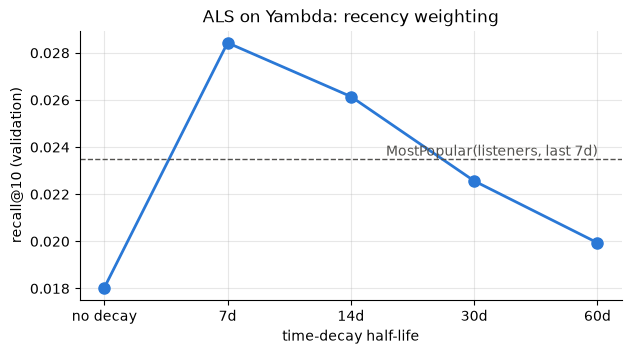

In [5]:
BLUE, GRAY = "#2a78d6", "#52514e"
rows = []
for hl_ in [None, 7, 14, 30, 60]:
    best = max(results[ALS(factors=64, alpha=a, half_life_days=hl_).name]["recall@10"] for a in [2, 10])
    rows.append(("no decay" if hl_ is None else f"{hl_}d", best))
labels, values = zip(*rows)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(labels, values, color=BLUE, lw=2, marker="o", markersize=8)
ax.axhline(results[best_pop]["recall@10"], color=GRAY, lw=1, ls="--")
ax.text(len(labels) - 1, results[best_pop]["recall@10"], f"  {best_pop}", va="bottom", ha="right", color=GRAY)
ax.set(xlabel="time-decay half-life", ylabel="recall@10 (validation)", title="ALS on Yambda: recency weighting")
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
config.YAMBDA_FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(config.YAMBDA_FIGURES_DIR / "y04_als_half_life.png", dpi=150, bbox_inches="tight")

## Secondary targets (organic + recommended discoveries)

In [6]:
compare = [best_pop, best_knn, best_als]
pd.DataFrame({n: evaluate(models[n], split, targets=targets_all) for n in compare}).T[
    ["recall@10", "ndcg@10", "hit_rate@10", "n_eval_users"]]

,recall@10,ndcg@10,hit_rate@10,n_eval_users
"MostPopular(listeners, last 7d)",0.0391,0.0401,0.2036,"7,145.0000"
"ItemKNN(k=100, shrink=1.0, log, half-life 7d)",0.0613,0.0628,0.2861,"7,145.0000"
"ALS(f=128, reg=0.05, alpha=10, half-life 7d)",0.0719,0.0712,0.3656,"7,145.0000"


## Familiar vs. new artists

1. Segment the targets: discoveries by an artist the user already knows vs. a new artist.
2. How many of each model's top-10 slots go to known artists?
3. Fair new-artist comparison: every model may only recommend new-artist tracks.

In [7]:
item_artist = load_item_artist()
lens = ArtistLens(split, item_artist)
new_artist = artist_novelty(split, item_artist)
print(f"main targets by an artist the user already knows: {1 - new_artist.mean():.1%}")

rows = {}
for n in compare:
    m = models[n]
    known_seg = evaluate(m, split, targets=split.targets[~new_artist])
    new_seg = evaluate(m, split, targets=split.targets[new_artist])
    fair = evaluate(ExcludeKnownArtists(m, lens), split, targets=split.targets[new_artist])
    rows[n] = {
        "known-artist slots in top-10": known_artist_share(m, split, lens),
        "recall@10 | known-artist targets": known_seg["recall@10"],
        "recall@10 | new-artist targets": new_seg["recall@10"],
        "recall@10 | new-artist, new-artist-only lists": fair["recall@10"],
    }
pd.DataFrame(rows).T

main targets by an artist the user already knows: 41.7%


,known-artist slots in top-10,recall@10 | known-artist targets,recall@10 | new-artist targets,"recall@10 | new-artist, new-artist-only lists"
"MostPopular(listeners, last 7d)",0.2435,0.0187,0.0188,0.0283
"ItemKNN(k=100, shrink=1.0, log, half-life 7d)",0.5482,0.0280,0.0077,0.0156
"ALS(f=128, reg=0.05, alpha=10, half-life 7d)",0.5823,0.0336,0.0147,0.0313
